# The Magnificent Seven Dashboard

**Question:** How have the seven biggest US tech stocks performed, how risky was the ride, and how much do they actually diversify each other?

**Stocks:** Apple (AAPL), Microsoft (MSFT), Alphabet (GOOGL), Amazon (AMZN), Nvidia (NVDA), Meta (META), Tesla (TSLA)

**Benchmark:** S&P 500, via the SPY fund

**Stack:** pandas, NumPy, Matplotlib, yfinance

The notebook runs top to bottom: load prices → check the data → compute metrics → draw the dashboard → run an honesty check.

> First time only: open Anaconda Prompt and run `pip install yfinance`.

## 1. Setup

Everything you might want to change lives in this one cell.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import FuncFormatter, FixedLocator, NullLocator

# --- Settings -------------------------------------------------------------
TICKERS = ["AAPL", "MSFT", "GOOGL", "AMZN", "NVDA", "META", "TSLA"]
BENCHMARK = "SPY"            # S&P 500 fund, used as the comparison line
START = "2021-11-01"         # first day of the analysis window
END = None                   # None = up to the latest available day
RISK_FREE = 0.04             # yearly risk-free rate used in the Sharpe ratio
TRADING_DAYS = 252           # trading days in a year
CACHE = Path("m7_prices.csv")        # prices are saved here after download
REFRESH = False              # True = download again even if the cache exists
OUTPUT = Path("magnificent_seven_dashboard.png")

## 2. Load prices

`yfinance` pulls daily prices from Yahoo Finance. `auto_adjust=True` gives prices adjusted for splits and dividends, so a 4-for-1 split doesn't look like a 75% crash.

The download is saved to a CSV. Later runs read the CSV, so the notebook still works offline and the numbers don't shift under you mid-analysis. Set `REFRESH = True` to pull fresh data.

In [2]:
def load_prices(tickers, start, end=None, cache=CACHE, refresh=REFRESH):
    # Return a table of daily adjusted closing prices, one column per ticker.
    if cache.exists() and not refresh:
        return pd.read_csv(cache, index_col=0, parse_dates=True)

    import yfinance as yf
    raw = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)
    prices = raw["Close"][tickers]          # keep our column order
    prices.index.name = "Date"
    prices.to_csv(cache)
    return prices


prices_raw = load_prices(TICKERS + [BENCHMARK], START, END)
prices_raw.tail()

,AAPL,MSFT,GOOGL,AMZN,NVDA,META,TSLA,SPY
Date,,,,,,,,
2026-11-10,348.245392,533.159973,287.380005,270.869995,168.889999,641.390015,379.779999,749.919983
2026-11-11,355.359985,521.130005,293.450012,266.170013,173.729996,628.770020,390.839996,759.809998
2026-11-12,354.880005,523.000000,298.700012,267.440002,166.190002,623.609985,397.450012,757.119995
2026-11-13,356.269989,523.880005,295.769989,266.660004,162.850006,641.690002,390.220001,754.369995
2026-11-16,352.779999,517.989990,283.720001,257.750000,156.139999,626.409973,379.739990,739.960022


## 3. Check the data

Never chart data you haven't looked at. Three quick checks: how many rows, what dates, and are there gaps?

In [3]:
print(f"Rows: {len(prices_raw):,}")
print(f"From: {prices_raw.index.min():%b %d, %Y}")
print(f"To:   {prices_raw.index.max():%b %d, %Y}")
print()
print("Missing values per ticker:")
print(prices_raw.isna().sum().to_string())

# Keep only days where every ticker has a price, so all comparisons are like-for-like.
prices = prices_raw.dropna()
dropped = len(prices_raw) - len(prices)
print(f"\nDropped {dropped} incomplete day(s). {len(prices):,} trading days remain.")

assert (prices > 0).all().all(), "Found a zero or negative price. Check the download."

Rows: 1,266
From: Nov 01, 2021
To:   Nov 16, 2026

Missing values per ticker:
AAPL     0
MSFT     0
GOOGL    0
AMZN     0
NVDA     0
META     0
TSLA     0
SPY      0

Dropped 0 incomplete day(s). 1,266 trading days remain.


## 4. Compute the metrics

- **Daily return:** percent change from one close to the next.
- **Equal-weight portfolio:** one-seventh in each stock, rebalanced daily. Its daily return is the average of the seven daily returns.
- **Growth of $100:** what $100 invested on day one would be worth.
- **CAGR:** the steady yearly growth rate that gets you from start to finish.
- **Volatility:** how much daily returns bounce around, scaled to a year.
- **Sharpe ratio:** return above the risk-free rate, per unit of volatility. Higher is better.
- **Drawdown:** how far below its previous peak a stock is sitting. Max drawdown is the worst of those.

In [4]:
PORT = "Equal-weight M7"
BENCH = "S&P 500"

returns = prices.pct_change().dropna()
returns = returns.rename(columns={BENCHMARK: BENCH})
returns[PORT] = returns[TICKERS].mean(axis=1)

growth = 100 * (1 + returns).cumprod()            # growth of $100
drawdown = growth / growth.cummax() - 1           # 0 at a peak, negative below it

years = len(returns) / TRADING_DAYS

metrics = pd.DataFrame({
    "Total return": growth.iloc[-1] / 100 - 1,
    "CAGR": (growth.iloc[-1] / 100) ** (1 / years) - 1,
    "Volatility": returns.std() * np.sqrt(TRADING_DAYS),
    "Max drawdown": drawdown.min(),
    "Best day": returns.max(),
    "Worst day": returns.min(),
})
metrics["Sharpe"] = (metrics["CAGR"] - RISK_FREE) / metrics["Volatility"]

corr = returns[TICKERS].corr()

(metrics.sort_values("Total return", ascending=False)
        .style.format({c: "{:.1%}" for c in metrics.columns if c != "Sharpe"} | {"Sharpe": "{:.2f}"}))

,Total return,CAGR,Volatility,Max drawdown,Best day,Worst day,Sharpe
NVDA,507.2%,43.2%,52.1%,-66.3%,24.4%,-17.0%,0.75
Equal-weight M7,149.4%,20.0%,30.2%,-49.4%,14.8%,-7.1%,0.53
AAPL,143.0%,19.3%,28.1%,-33.4%,15.3%,-9.2%,0.55
GOOGL,99.6%,14.8%,32.6%,-44.3%,10.2%,-12.6%,0.33
META,91.7%,13.8%,45.3%,-74.4%,23.3%,-26.4%,0.22
S&P 500,72.0%,11.4%,17.3%,-24.5%,10.5%,-5.9%,0.43
MSFT,63.9%,10.3%,28.4%,-37.1%,15.5%,-10.0%,0.22
AMZN,55.4%,9.2%,36.7%,-55.7%,15.3%,-14.0%,0.14
TSLA,-5.7%,-1.2%,59.7%,-73.6%,22.7%,-15.4%,-0.09


## 5. Design system

A trading-terminal look built for this dashboard: a near-black surface, an amber accent, monospaced figures that line up like a quote screen, and ▲ / ▼ markers for gains and losses.

Two rules worth keeping:
- **Color follows the stock.** NVDA is the same color in every panel.
- **Text is never colored.** Labels stay in neutral ink and a colored dot or arrow next to them carries the meaning. This keeps the chart readable for colorblind viewers.
- **Green and red mean gain and loss, nothing else.** They always come with an arrow, so the meaning never rests on color alone.

The seven colors were checked for colorblind separation and contrast against the dark background.

In [5]:
# Surfaces and ink
SURFACE = "#0b0e11"      # page background
PANEL = "#12161b"        # card background
GRID = "#232a32"         # gridlines and borders
TEXT = "#eef1f4"         # primary text
TEXT_2 = "#b6bec8"       # secondary text
TEXT_3 = "#7d8792"       # muted text
CONTEXT = "#7d8792"      # the benchmark line
ACCENT = "#f5a623"       # terminal amber, used for headings only (never for data)
GAIN = "#0ca30c"         # ▲ up
LOSS = "#e66767"         # ▼ down
# Monospaced font for figures: the first one installed on this computer
from matplotlib import font_manager
_installed = {f.name for f in font_manager.fontManager.ttflist}
MONO = next(f for f in ["Consolas", "Menlo", "DejaVu Sans Mono"] if f in _installed)

# One fixed color per stock
COLORS = {
    "AAPL": "#3987e5",   # blue
    "MSFT": "#d95926",   # orange
    "GOOGL": "#199e70",  # aqua
    "AMZN": "#c98500",   # yellow
    "NVDA": "#d55181",   # magenta
    "META": "#0ca30c",   # green
    "TSLA": "#9085e9",   # violet
    PORT: TEXT,
    BENCH: CONTEXT,
}

# Correlation scale: blue = move opposite, gray = unrelated, red = move together
CORR_CMAP = LinearSegmentedColormap.from_list("corr", ["#3987e5", "#2a3038", "#e66767"])

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Inter", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10,
    "figure.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.facecolor": PANEL,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_2,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": TEXT_3,
    "ytick.color": TEXT_3,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "text.color": TEXT,
    "lines.linewidth": 2,
    "lines.solid_capstyle": "round",
    "lines.solid_joinstyle": "round",
})


def style_axes(ax, title, subtitle=None):
    # Shared look for every chart panel: no box, quiet ticks, left-aligned title.
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)
    ax.set_title(title.upper(), loc="left", fontsize=12, fontweight="bold", color=ACCENT, pad=22 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.025, subtitle, transform=ax.transAxes, fontsize=9.5, color=TEXT_3, va="bottom")


def spread_labels(values, min_gap):
    # Nudge label positions apart so text doesn't overlap. Returns new positions.
    order = np.argsort(values)
    out = np.array(values, dtype=float)
    for a, b in zip(order[:-1], order[1:]):
        if out[b] - out[a] < min_gap:
            out[b] = out[a] + min_gap
    return out


def pct(x, digits=0):
    x = round(x, digits + 2) + 0.0          # avoids printing "-0%"
    return f"{x:+.{digits}%}"


def arrow(x):
    # Marker and color for a gain or a loss.
    return ("▲", GAIN) if x >= 0 else ("▼", LOSS)

## 6. The dashboard

A ticker tape of total returns on top (SR = Sharpe ratio), then four views: growth, risk against return, correlation, and drawdowns.

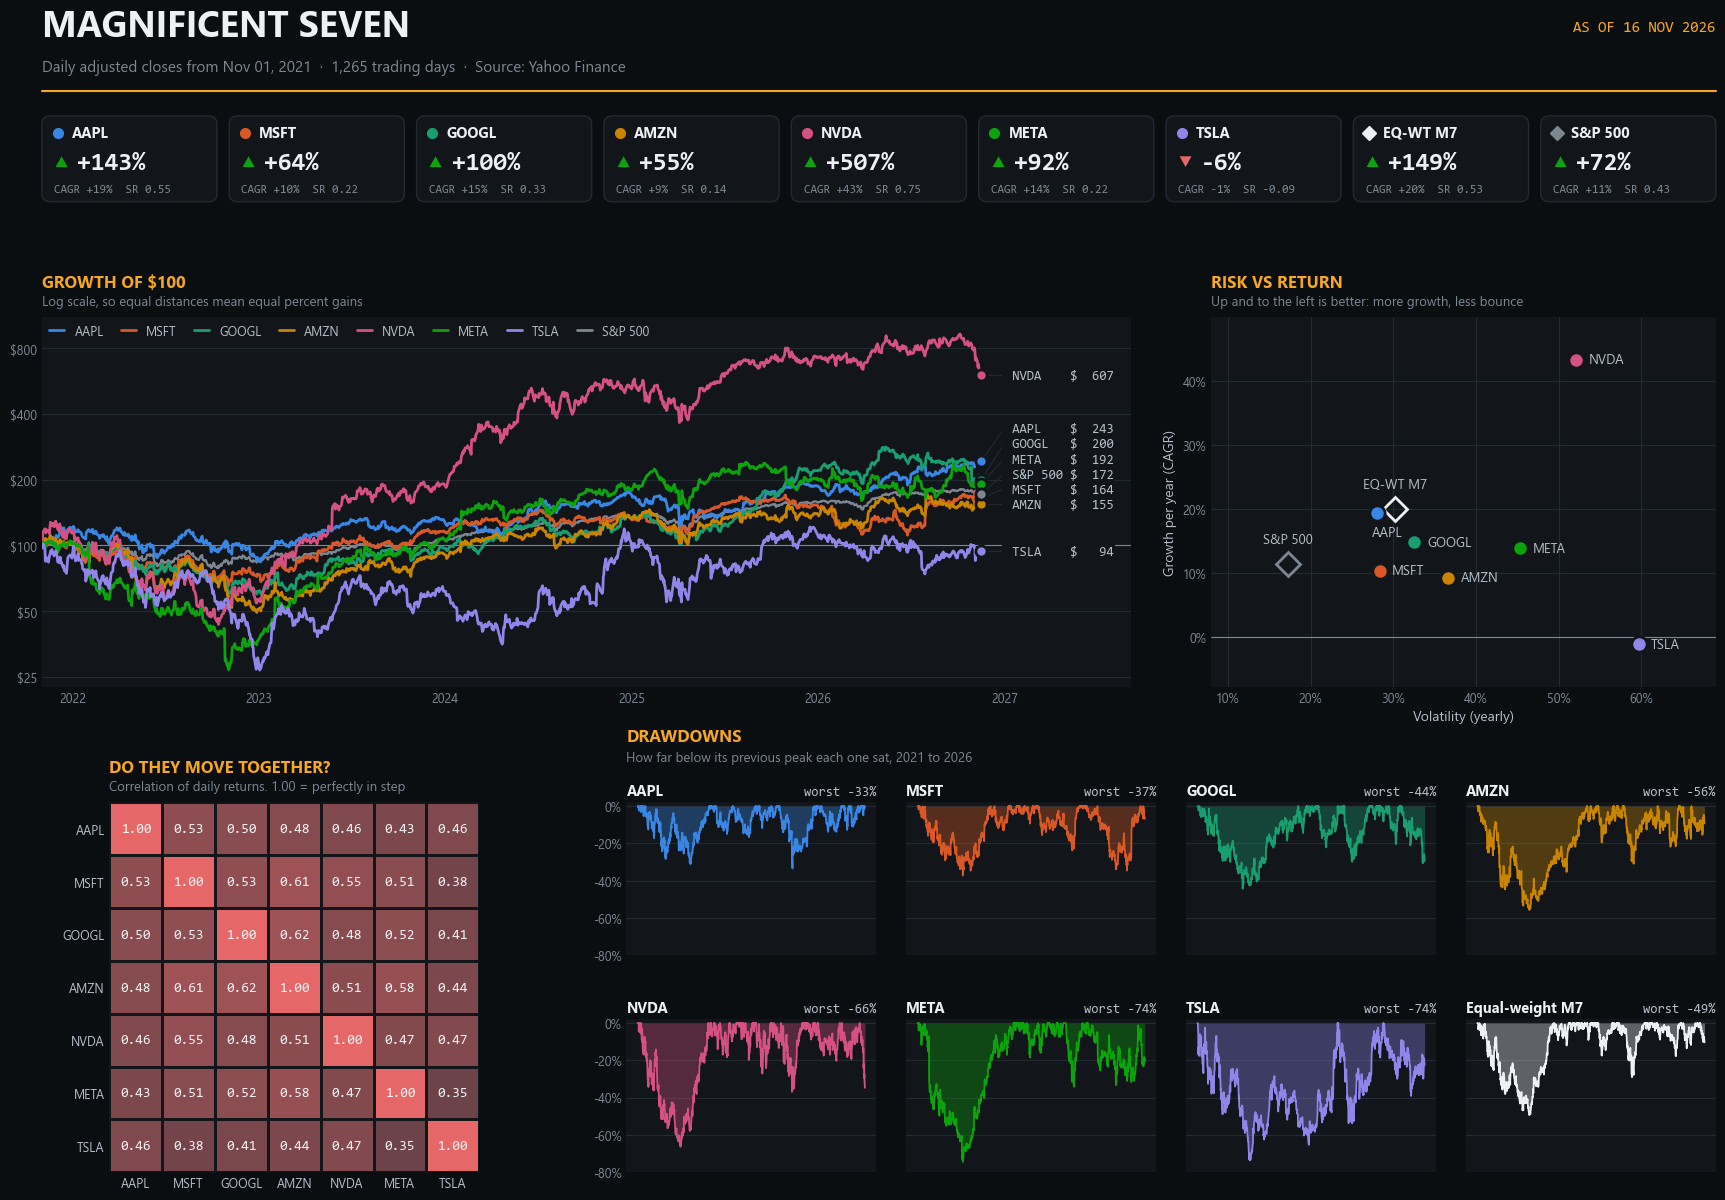

Saved magnificent_seven_dashboard.png


In [6]:
fig = plt.figure(figsize=(18, 12.5))
gs = GridSpec(3, 12, figure=fig, height_ratios=[0.72, 3.1, 3.1],
              left=0.04, right=0.97, top=0.895, bottom=0.05, hspace=0.42, wspace=1.2)

# ---- Header ---------------------------------------------------------------
fig.text(0.04, 0.966, "MAGNIFICENT SEVEN", fontsize=26, fontweight="bold", color=TEXT, va="center")
fig.text(0.97, 0.966, f"AS OF {prices.index.max():%d %b %Y}".upper(), fontsize=11, color=ACCENT,
         va="center", ha="right", fontfamily=MONO)
fig.text(0.04, 0.934,
         f"Daily adjusted closes from {prices.index.min():%b %d, %Y}"
         f"  ·  {len(returns):,} trading days  ·  Source: Yahoo Finance",
         fontsize=11, color=TEXT_3, va="center")
fig.add_artist(plt.Line2D([0.04, 0.97], [0.915, 0.915], color=ACCENT, linewidth=1.5))

# ---- Ticker tape: one quote tile per stock, plus the portfolio and benchmark
tape = TICKERS + [PORT, BENCH]
tape_gs = gs[0, :].subgridspec(1, len(tape), wspace=0.07)
for i, name in enumerate(tape):
    m = metrics.loc[name]
    ax = fig.add_subplot(tape_gs[0, i])
    ax.set_axis_off()
    ax.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0,rounding_size=0.05",
                                transform=ax.transAxes, facecolor=PANEL, edgecolor=GRID,
                                linewidth=1, mutation_aspect=1.9, clip_on=False))
    ax.plot([0.09], [0.8], "o" if name in TICKERS else "D", markersize=7, color=COLORS[name],
            transform=ax.transAxes, clip_on=False)
    ax.text(0.17, 0.8, "EQ-WT M7" if name == PORT else name.upper(), fontsize=10.5, fontweight="bold",
            color=TEXT, va="center", transform=ax.transAxes)
    mark, mark_color = arrow(round(m["Total return"], 2) + 0.0)
    ax.text(0.07, 0.46, mark, fontsize=11, color=mark_color, va="center", transform=ax.transAxes)
    ax.text(0.2, 0.46, pct(m["Total return"]), fontsize=18, fontweight="bold", color=TEXT,
            va="center", transform=ax.transAxes, fontfamily=MONO)
    ax.text(0.07, 0.15, f"CAGR {pct(m['CAGR'])}  SR {m['Sharpe']:.2f}", fontsize=8.5, color=TEXT_3,
            va="center", transform=ax.transAxes, fontfamily=MONO)

# ---- Growth of $100 --------------------------------------------------------
ax = fig.add_subplot(gs[1, :8])
style_axes(ax, "Growth of $100", "Log scale, so equal distances mean equal percent gains")
ax.set_yscale("log")
ax.plot(growth.index, growth[BENCH], color=CONTEXT, linewidth=1.6, zorder=2)
for t in TICKERS:
    ax.plot(growth.index, growth[t], color=COLORS[t], zorder=3)

# End-of-line labels, spread apart so they don't collide
names = TICKERS + [BENCH]
last = growth[names].iloc[-1]
lo, hi = np.log10(growth[names].min().min()), np.log10(growth[names].max().max())
label_y = 10 ** spread_labels(np.log10(last.values), min_gap=(hi - lo) * 0.045)
x_end = growth.index[-1]
x_label = x_end + (growth.index[-1] - growth.index[0]) * 0.025
for name, y_true, y_text in zip(names, last.values, label_y):
    ax.plot([x_end], [y_true], "o", markersize=8, color=COLORS[name],
            markeredgecolor=PANEL, markeredgewidth=2, zorder=4, clip_on=False)
    ax.plot([x_end, x_label], [y_true, y_text], color=GRID, linewidth=0.8, zorder=1, clip_on=False)
    ax.text(x_label, y_text, f" {name:<7} ${y_true:>5,.0f}", fontsize=9.5, color=TEXT_2,
            va="center", ha="left", clip_on=False, fontfamily=MONO,
            bbox=dict(facecolor=PANEL, edgecolor="none", pad=1.5))
ax.set_xlim(growth.index[0], x_end + (growth.index[-1] - growth.index[0]) * 0.16)
ax.axhline(100, color=TEXT_3, linewidth=0.8, zorder=1)
ticks = [t for t in (25, 50, 100, 200, 400, 800, 1600, 3200) if 10 ** lo * 0.8 <= t <= 10 ** hi * 1.25]
ax.yaxis.set_major_locator(FixedLocator(ticks))
ax.yaxis.set_minor_locator(NullLocator())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.grid(axis="x", visible=False)
handles = [plt.Line2D([], [], color=COLORS[n], linewidth=2, label=n) for n in names]
ax.legend(handles=handles, ncol=len(names), loc="upper left", frameon=False, fontsize=9,
          labelcolor=TEXT_2, handlelength=1.2, columnspacing=1.4, borderaxespad=0.2)

# ---- Risk vs return --------------------------------------------------------
ax = fig.add_subplot(gs[1, 8:])
style_axes(ax, "Risk vs return", "Up and to the left is better: more growth, less bounce")
refs = [PORT, BENCH]
x_span = metrics.loc[TICKERS + refs, "Volatility"].max() - metrics.loc[TICKERS + refs, "Volatility"].min()
y_span = metrics.loc[TICKERS + refs, "CAGR"].max() - metrics.loc[TICKERS + refs, "CAGR"].min()

# Portfolio and benchmark: hollow diamonds drawn behind the stocks, labels above
for name in refs:
    x, y = metrics.loc[name, "Volatility"], metrics.loc[name, "CAGR"]
    ax.plot(x, y, "D", markersize=12, markerfacecolor="none", markeredgecolor=COLORS[name],
            markeredgewidth=2, zorder=2)
    ax.annotate("EQ-WT M7" if name == PORT else name, (x, y), xytext=(0, 13),
                textcoords="offset points", fontsize=9.5, color=TEXT_2, va="bottom", ha="center")

# Stocks: filled dots on top, labels to the right
for name in TICKERS:
    x, y = metrics.loc[name, "Volatility"], metrics.loc[name, "CAGR"]
    ax.plot(x, y, "o", markersize=11, color=COLORS[name], markeredgecolor=PANEL,
            markeredgewidth=2, zorder=3)
    # If a diamond sits right next to this dot, drop the label below so they don't collide
    crowded = any(abs(metrics.loc[r, "Volatility"] - x) < 0.08 * x_span and
                  abs(metrics.loc[r, "CAGR"] - y) < 0.08 * y_span for r in refs)
    ax.annotate(name, (x, y), xytext=(-4, -14) if crowded else (9, 0), textcoords="offset points",
                fontsize=9.5, color=TEXT_2, va="center", zorder=4)
ax.axhline(0, color=TEXT_3, linewidth=0.8, zorder=1)
ax.margins(x=0.22, y=0.15)
ax.set_xlabel("Volatility (yearly)")
ax.set_ylabel("Growth per year (CAGR)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))

# ---- Correlation heatmap ---------------------------------------------------
ax = fig.add_subplot(gs[2, :4])
style_axes(ax, "Do they move together?", "Correlation of daily returns. 1.00 = perfectly in step")
n = len(TICKERS)
ax.pcolormesh(corr.values, cmap=CORR_CMAP, vmin=-1, vmax=1, edgecolors=PANEL, linewidth=2)
for i in range(n):
    for j in range(n):
        ax.text(j + 0.5, i + 0.5, f"{corr.values[i, j]:.2f}", ha="center", va="center",
                fontsize=10, color=TEXT, fontfamily=MONO)
ax.set_xticks(np.arange(n) + 0.5, TICKERS)
ax.set_yticks(np.arange(n) + 0.5, TICKERS)
ax.tick_params(colors=TEXT_2)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.grid(False)

# ---- Drawdowns, one small panel per stock ----------------------------------
dd_names = TICKERS + [PORT]
dd_gs = gs[2, 4:].subgridspec(2, 4, hspace=0.42, wspace=0.12)
dd_floor = np.floor(drawdown[dd_names].min().min() * 10) / 10
first = None
for k, name in enumerate(dd_names):
    ax = fig.add_subplot(dd_gs[k // 4, k % 4], sharey=first)
    first = first or ax
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)
    ax.fill_between(drawdown.index, drawdown[name], 0, color=COLORS[name], alpha=0.35, linewidth=0)
    ax.plot(drawdown.index, drawdown[name], color=COLORS[name], linewidth=1.3)
    ax.set_ylim(dd_floor, 0.02)
    ax.set_title(name, loc="left", fontsize=10.5, fontweight="bold", color=TEXT, pad=5)
    ax.set_title(f"worst {drawdown[name].min():.0%}", loc="right", fontsize=9.5, color=TEXT_2, pad=5,
                 fontfamily=MONO)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.xaxis.set_major_locator(FixedLocator([]))
    ax.grid(axis="x", visible=False)
    if k % 4:
        ax.tick_params(labelleft=False)
    if k == 0:
        ax.text(0, 1.4, "DRAWDOWNS", transform=ax.transAxes, fontsize=12, fontweight="bold", color=ACCENT)
        ax.text(0, 1.27, f"How far below its previous peak each one sat, {prices.index.min():%Y} to {prices.index.max():%Y}",
                transform=ax.transAxes, fontsize=9.5, color=TEXT_3)

fig.savefig(OUTPUT, dpi=150)
plt.show()
print(f"Saved {OUTPUT}")

## 7. Honesty check: is a pattern real, or just the market drifting up?

Stocks rise on slightly more than half of all days. So a "model" that predicts **up** every single day already scores above 50% without knowing anything. Any signal has to beat that dumb baseline before it means something.

Here's a tiny test. The **momentum rule** says: tomorrow goes the same direction as today. Compare its accuracy with **always up**.

In [7]:
up = returns[TICKERS] > 0
today, tomorrow = up.iloc[:-1].values, up.iloc[1:].values

check = pd.DataFrame({
    "Always up": tomorrow.mean(axis=0),
    "Momentum rule": (today == tomorrow).mean(axis=0),
}, index=TICKERS)
check["Edge over baseline"] = check["Momentum rule"] - check["Always up"]

# How big an edge could appear by pure chance? Roughly two standard errors.
noise = 2 * np.sqrt(0.25 / len(tomorrow))
print(f"With {len(tomorrow):,} days, an edge smaller than about ±{noise:.1%} is indistinguishable from luck.\n")
check.style.format("{:.1%}")

With 1,264 days, an edge smaller than about ±2.8% is indistinguishable from luck.



,Always up,Momentum rule,Edge over baseline
AAPL,53.0%,50.4%,-2.6%
MSFT,51.7%,50.1%,-1.6%
GOOGL,52.1%,50.7%,-1.4%
AMZN,50.9%,50.0%,-0.9%
NVDA,52.5%,51.3%,-1.2%
META,51.3%,49.8%,-1.4%
TSLA,50.7%,50.9%,0.2%


## 8. What I found

*Write this section yourself after running the notebook. Prompts to get started:*

- Which stock grew the most, and what did holding it cost in volatility and drawdown?
- Does the equal-weight portfolio beat the S&P 500 once you account for risk (Sharpe)? Or is it the same bet with more bounce?
- Look at the correlation grid. Do seven stocks give you seven bets, or closer to one?
- Did the momentum rule beat "always up" by more than the luck threshold for any stock?

**Limits of this analysis**

- The seven were picked *because* they won. Looking back at known winners overstates what you could have earned by choosing in advance (survivorship bias).
- The start date matters. Change `START` and see how much the story shifts.
- Past returns say nothing certain about future returns. This is analysis practice, not investment advice.